## Install Required Libraries :

In [1]:
!pip install -q ultralytics datasets huggingface_hub PyYAML pillow matplotlib pandas scikit-learn opencv-python

## Import Dependencies & Verify GPU :

In [2]:
import os
import re
import time
import shutil
from pathlib import Path
from collections import Counter, defaultdict

import yaml
import cv2
import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from datasets import load_dataset
from huggingface_hub import snapshot_download
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"
print(f"PyTorch version: {torch.__version__} | Active device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.14.1+cu130 | Active device: 0
GPU Name: Tesla T4


## Download & Inspect Dataset Structure


In [3]:
REPO_ID = "Simuletic/CCTV-Smoke-Fire-Emergency-Detection-Dataset"

# 1. Load via Hugging Face datasets library
ds = load_dataset(REPO_ID)
print("Hugging Face DatasetDict:", ds)

# 2. Download raw repository snapshot to access original images and YOLO .txt labels
raw_repo_dir = Path(snapshot_download(repo_id=REPO_ID, repo_type="dataset"))
print("Raw repository path:", raw_repo_dir)

image_extensions = {".jpg", ".jpeg", ".png"}
all_images = sorted([
    p for p in raw_repo_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
])
all_labels = {
    p.stem: p for p in raw_repo_dir.rglob("*.txt")
    if p.is_file() and p.name.lower() not in {"readme.txt", "classes.txt", "license.txt"}
}

print(f"Total image files found: {len(all_images)}")
print(f"Total YOLO .txt label files found: {len(all_labels)}")

Resolving data files:   0%|          | 0/479 [00:00<?, ?it/s]

Hugging Face DatasetDict: DatasetDict({
    train: Dataset({
        features: ['image'],
        num_rows: 240
    })
})


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 482 files:   0%|          | 0/482 [00:00<?, ?it/s]

Raw repository path: /root/.cache/huggingface/hub/datasets--Simuletic--CCTV-Smoke-Fire-Emergency-Detection-Dataset/snapshots/b9df600c82aa5033a31d0f8448ba4863698b978c
Total image files found: 240
Total YOLO .txt label files found: 239


## Verify Image-Label Pairs & Quarantine Missing Annotations :

In [4]:

valid_pairs = []
missing_label_images = []
empty_or_invalid_labels = []
class_counts = Counter()
image_sizes = Counter()

for img_path in all_images:
    lbl_path = all_labels.get(img_path.stem)
    if lbl_path is None or not lbl_path.exists():
        # Do NOT silently treat images missing a label file as negative examples
        missing_label_images.append(img_path)
        continue

    lines = [ln.strip() for ln in lbl_path.read_text(encoding="utf-8", errors="ignore").splitlines() if ln.strip()]
    if not lines:
        empty_or_invalid_labels.append((img_path, lbl_path))
        continue

    valid_boxes = []
    for line in lines:
        parts = line.split()
        if len(parts) >= 5:
            cls_id = int(float(parts[0]))
            coords = [float(x) for x in parts[1:5]]
            if cls_id in (0, 1):
                valid_boxes.append((cls_id, *coords))
                class_counts[cls_id] += 1

    if not valid_boxes:
        empty_or_invalid_labels.append((img_path, lbl_path))
        continue

    with Image.open(img_path) as im:
        image_sizes[im.size] += 1

    valid_pairs.append((img_path, lbl_path))

print(f"Valid image-label pairs: {len(valid_pairs)}")
print(f"Excluded images missing annotation file: {len(missing_label_images)}")
for m in missing_label_images:
    print(f"  -> Quarantined unannotated image: {m.name}")
print(f"Excluded empty/invalid label files: {len(empty_or_invalid_labels)}")
print(f"Bounding box counts by class (0=fire, 1=smoke): {dict(class_counts)}")
print(f"Image dimensions (width, height): {dict(image_sizes)}")

Valid image-label pairs: 239
Excluded images missing annotation file: 1
  -> Quarantined unannotated image: fire_detected_var16_img3.png
Excluded empty/invalid label files: 0
Bounding box counts by class (0=fire, 1=smoke): {0: 121, 1: 141}
Image dimensions (width, height): {(1024, 1024): 239}


## Create Train / Val / Test Splits & YOLO Folder Structure :

In [5]:
def extract_scene_group(stem: str) -> str:
    """
    Groups multi-frame clips from the same camera scene while preventing
    generic 2-token prefixes from collapsing all 239 images into one group.
    """
    tokens = re.split(r"[_\-]", stem)
    if len(tokens) >= 3:
        return "_".join(tokens[:-1])
    return stem

scene_groups = defaultdict(list)
for img_path, lbl_path in valid_pairs:
    grp = extract_scene_group(img_path.stem)
    scene_groups[grp].append((img_path, lbl_path))

# Fallback: if filenames share a single prefix and form fewer than 10 groups,
# assign each valid pair its own group key so train/val/test splits are guaranteed non-empty.
if len(scene_groups) < 10:
    scene_groups = {f"item_{i:04d}": [pair] for i, pair in enumerate(valid_pairs)}

rng = np.random.default_rng(seed=42)
group_keys = sorted(scene_groups.keys())
rng.shuffle(group_keys)

total_valid = len(valid_pairs)
train_target = int(round(total_valid * 0.75))        # ~179 images
val_target = max(1, int(round(total_valid * 0.15)))  # ~36 images
# Remaining ~10% (~24 images) go to test

splits = {"train": [], "val": [], "test": []}
for g in group_keys:
    items = scene_groups[g]
    if len(splits["train"]) + len(items) <= train_target or len(splits["train"]) == 0:
        splits["train"].extend(items)
    elif len(splits["val"]) + len(items) <= val_target or len(splits["val"]) == 0:
        splits["val"].extend(items)
    else:
        splits["test"].extend(items)

dataset_root = Path("dataset").resolve()
if dataset_root.exists():
    shutil.rmtree(dataset_root)

for split_name, pairs in splits.items():
    img_dir = dataset_root / "images" / split_name
    lbl_dir = dataset_root / "labels" / split_name
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for img_p, lbl_p in pairs:
        shutil.copy2(img_p, img_dir / img_p.name)
        shutil.copy2(lbl_p, lbl_dir / f"{img_p.stem}.txt")
    print(f"Split '{split_name}': {len(pairs)} image-label pairs")

# Clean any old Ultralytics .cache files
for cache_file in dataset_root.rglob("*.cache"):
    cache_file.unlink(missing_ok=True)

assert len(splits["train"]) > 0, "ERROR: train split is empty!"
assert len(splits["val"]) > 0, "ERROR: val split is empty!"

Split 'train': 179 image-label pairs
Split 'val': 35 image-label pairs
Split 'test': 25 image-label pairs


## Generate fire_smoke.yaml Configuration :

In [6]:
yaml_config = {
    "path": str(dataset_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "fire",
        1: "smoke"
    }
}

yaml_path = Path("fire_smoke.yaml").resolve()
with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(yaml_config, f, sort_keys=False)

print(f"Saved YAML config to {yaml_path}:\n")
print(yaml_path.read_text(encoding="utf-8"))

Saved YAML config to /content/fire_smoke.yaml:

path: /content/dataset
train: images/train
val: images/val
test: images/test
names:
  0: fire
  1: smoke



## Fine-Tune Pretrained YOLO26n Model (Transfer Learning) :

In [7]:
model = YOLO("yolo26n.pt")

train_results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=8,
    pretrained=True,
    patience=10,
    device=device,
    project="FireWatch_Runs",
    name="firewatch_yolo26n",
    exist_ok=True
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire_smoke.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=firewatch_yolo26n, nbs=64, nms=None, opset=None, optimize=False, 

## Export Best Checkpoint (best.pt) & Evaluate on Val and Test Sets :

In [8]:
best_ckpt = Path(model.trainer.best) if hasattr(model, "trainer") and model.trainer is not None else Path("")

if not best_ckpt.exists():
    # Fallback search in case Ultralytics nested the save_dir
    candidates = sorted(Path(".").rglob("weights/best.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if candidates:
        best_ckpt = candidates[0]
    else:
        raise FileNotFoundError("best.pt was not found. Ensure Cell 7 finished training without errors.")

output_best = Path("best.pt").resolve()
shutil.copy2(best_ckpt, output_best)
print(f"Successfully copied best checkpoint from '{best_ckpt}' -> '{output_best}'")

# Load best.pt and evaluate on Validation and Held-Out Test splits
best_model = YOLO(str(output_best))

print("\n--- Validation Set Evaluation ---")
val_metrics = best_model.val(data=str(yaml_path), split="val", plots=True)
print(f"Validation mAP50:    {val_metrics.box.map50:.4f}")
print(f"Validation mAP50-95: {val_metrics.box.map:.4f}")
print(f"Class Precision (Fire, Smoke): {val_metrics.box.p}")
print(f"Class Recall    (Fire, Smoke): {val_metrics.box.r}")

if len(list((dataset_root / "images" / "test").glob("*"))) > 0:
    print("\n--- Held-Out Test Set Evaluation ---")
    test_metrics = best_model.val(data=str(yaml_path), split="test", plots=True)
    print(f"Held-Out Test mAP50:    {test_metrics.box.map50:.4f}")
    print(f"Held-Out Test mAP50-95: {test_metrics.box.map:.4f}")

Successfully copied best checkpoint from '/content/runs/detect/FireWatch_Runs/firewatch_yolo26n/weights/best.pt' -> '/content/best.pt'

--- Validation Set Evaluation ---
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4845.1±1204.3 MB/s, size: 1471.9 KB)
val: Scanning /content/dataset/labels/val.cache... 35 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35 9.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.0s/it 3.1s
                   all         35         36      0.795      0.818      0.874      0.464
                  fire         25         26       0.89      0.935      0.979      0.458
                 smoke         10         10        0.7        0.7      0.769      0.469
Speed: 5.4ms preprocess, 13.1ms inference, 0.0ms loss, 3.7

## : Test Inference on Sample Test Images & Visualize Bounding Boxes :

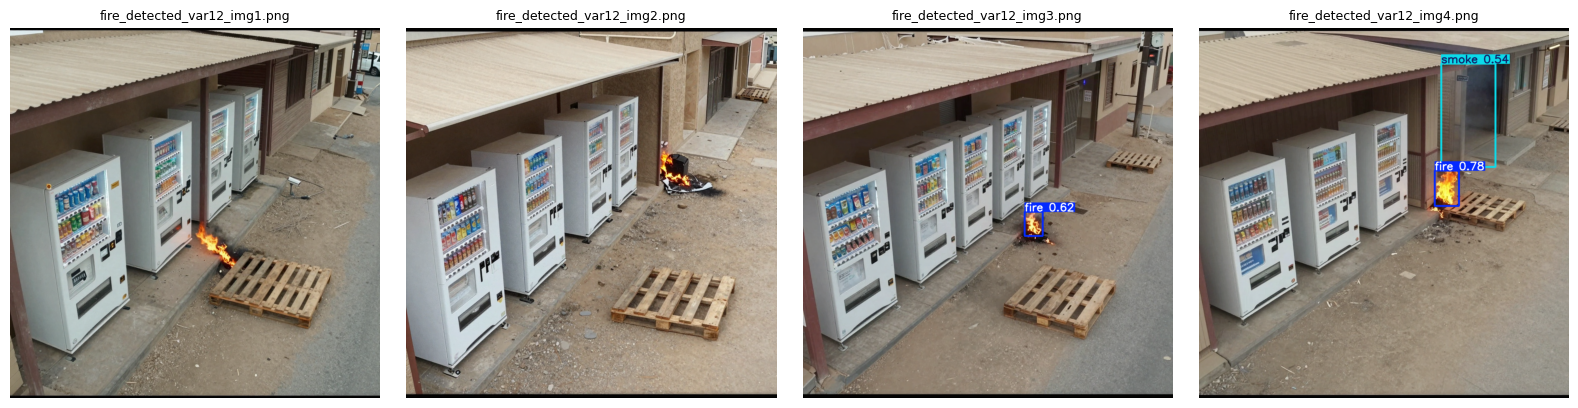

In [9]:
test_images = sorted((dataset_root / "images" / "test").glob("*"))[:4]
if not test_images:
    test_images = sorted((dataset_root / "images" / "val").glob("*"))[:4]

fig, axes = plt.subplots(1, len(test_images), figsize=(16, 4))
if len(test_images) == 1:
    axes = [axes]

for ax, img_p in zip(axes, test_images):
    preds = best_model.predict(source=str(img_p), conf=0.50, verbose=False)
    plotted_bgr = preds[0].plot()
    plotted_rgb = cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(plotted_rgb)
    ax.set_title(img_p.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Accuracy & Smoke Detection Improvement


In [10]:
def add_hard_negative_directory(neg_images_dir: str, split: str = "train") -> int:
    """
    Adds verified non-fire/non-smoke industrial images (steam, welding sparks, dust,
    exhaust, fog) to dataset/images/<split> with empty .txt YOLO annotation files
    in dataset/labels/<split> to reduce false alarms.
    """
    src_dir = Path(neg_images_dir)
    if not src_dir.exists():
        print(f"Hard-negative directory not found: {src_dir}")
        return 0

    img_out = dataset_root / "images" / split
    lbl_out = dataset_root / "labels" / split
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    added = 0
    for p in sorted(src_dir.rglob("*")):
        if p.is_file() and p.suffix.lower() in image_extensions:
            stem = f"hardneg_{p.stem}_{added:04d}"
            shutil.copy2(p, img_out / f"{stem}{p.suffix.lower()}")
            (lbl_out / f"{stem}.txt").write_text("", encoding="utf-8")
            added += 1

    print(f"Added {added} hard-negative image(s) with empty .txt label files to '{split}'.")
    return added


def fine_tune_improved_v2(epochs: int = 50, patience: int = 15):
    """
    Loads existing best.pt and runs incremental fine-tuning after you expand
    dataset/ with real-world Fire/Smoke images and empty-label Hard Negatives.
    """
    if not output_best.exists():
        raise FileNotFoundError("best.pt not found. Run Cells 7 and 8 first.")

    model_v2 = YOLO(str(output_best))
    model_v2.train(
        data=str(yaml_path),
        epochs=epochs,
        imgsz=640,
        batch=8,
        patience=patience,
        pretrained=True,
        device=device,
        project="FireWatch_Improved",
        name="fire_smoke_v2",
        exist_ok=True
    )
    return model_v2

print("Phase-2 helper functions ready (`add_hard_negative_directory`, `fine_tune_improved_v2`).")

Phase-2 helper functions ready (`add_hard_negative_directory`, `fine_tune_improved_v2`).


## Download Trained best.pt :

In [11]:

try:
    from google.colab import files
    print(f"Downloading {output_best} ({output_best.stat().st_size / (1024*1024):.2f} MB)...")
    files.download(str(output_best))
except ImportError:
    print(f"Not running in Google Colab. Your trained model is saved at: {output_best}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>